# 04 · Motor determinista de alertas

**Descargo metodológico:** una alerta indica que una señal estadística se activó. No certifica una quiebra, no califica al banco y no reemplaza el análisis financiero.

Se revisan las cinco señales del motor, los residuos estandarizados, el CUSUM y las alertas generadas para la serie seleccionada.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def raiz_proyecto():
    actual = Path.cwd()
    for base in [actual, *actual.parents]:
        if (base / "dashboard" / "data.json").exists():
            return base
    raise FileNotFoundError("Ejecute el notebook desde el repositorio del proyecto")

ROOT = raiz_proyecto()
datos = json.loads((ROOT / "dashboard" / "data.json").read_text(encoding="utf-8"))
BANCO = "bfort"
INDICADOR = "mora"
banco = next(b for b in datos["bancos"] if b["id"] == BANCO)
meta_indicador = next(i for i in datos["indicadores_meta"] if i["id"] == INDICADOR)
serie = datos["series"][BANCO][INDICADOR]
tabla = pd.DataFrame({
    "fecha": pd.to_datetime(serie["fechas"]),
    "valor": serie["observado"],
}).set_index("fecha")
tabla.head()

,valor
fecha,
2019-01-01,1.668071
2019-02-01,2.277313
2019-03-01,2.143988
2019-04-01,2.250342
2019-05-01,1.905817


## Residuos estandarizados y umbrales

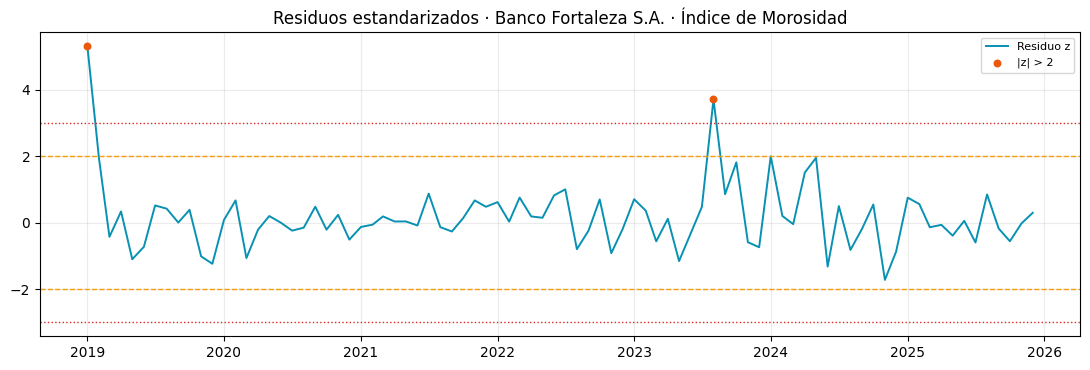

In [2]:
z = np.array(serie["residuos_estandarizados"], dtype=float)
fechas = pd.to_datetime(serie["fechas"])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(fechas, z, color="#0891b2", linewidth=1.4, label="Residuo z")
fuera = np.abs(z) > 2
ax.scatter(fechas[fuera], z[fuera], color="#ea580c", s=22, zorder=3, label="|z| > 2")
ax.axhline(2, color="#f59e0b", linestyle="--", linewidth=1)
ax.axhline(-2, color="#f59e0b", linestyle="--", linewidth=1)
ax.axhline(3, color="#dc2626", linestyle=":", linewidth=1)
ax.axhline(-3, color="#dc2626", linestyle=":", linewidth=1)
ax.set_title(f"Residuos estandarizados · {banco['nombre']} · {meta_indicador['nombre']}")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## CUSUM de residuos

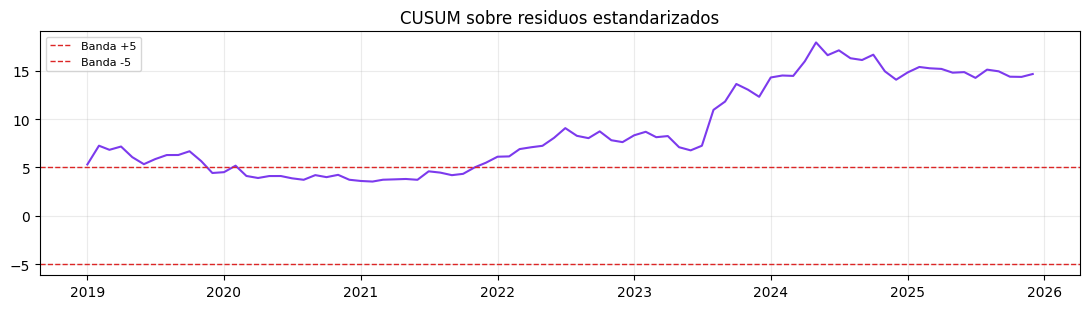

In [3]:
cusum = np.cumsum(z)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(fechas, cusum, color="#7c3aed", linewidth=1.5)
ax.axhline(5, color="#dc2626", linestyle="--", linewidth=1, label="Banda +5")
ax.axhline(-5, color="#dc2626", linestyle="--", linewidth=1, label="Banda -5")
ax.set_title("CUSUM sobre residuos estandarizados")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Alertas de la serie seleccionada

In [4]:
alertas = pd.DataFrame(datos["alertas"])
alertas["fecha_dt"] = pd.to_datetime(alertas["fecha"])
propias = alertas[(alertas["banco_id"] == BANCO) & (alertas["indicador_id"] == INDICADOR)].sort_values("fecha_dt", ascending=False)
propias[["fecha", "severidad", "z_score", "senales_activadas", "explicacion_clara"]].head(12)

,fecha,severidad,z_score,senales_activadas,explicacion_clara
146,2024-05,alerta,1.953175,[cusum],Banco Fortaleza S.A. · Índice de Morosidad (20...
203,2024-01,alerta,1.997453,[fuera_banda_95],Banco Fortaleza S.A. · Índice de Morosidad (20...
224,2023-10,vigilancia,1.815679,[racha_deterioro],Banco Fortaleza S.A. · Índice de Morosidad (20...
234,2023-09,alerta,0.859776,"[racha_deterioro, salto_estado]",Banco Fortaleza S.A. · Índice de Morosidad (20...
244,2023-08,critica,3.708963,"[fuera_banda_95, residuo_z_2, residuo_z_3]",Banco Fortaleza S.A. · Índice de Morosidad (20...
409,2022-07,vigilancia,1.004385,[racha_deterioro],Banco Fortaleza S.A. · Índice de Morosidad (20...
424,2022-06,alerta,0.823247,"[racha_deterioro, salto_estado]",Banco Fortaleza S.A. · Índice de Morosidad (20...
434,2022-05,vigilancia,0.148833,[racha_deterioro],Banco Fortaleza S.A. · Índice de Morosidad (20...
535,2021-07,alerta,0.874842,[salto_estado],Banco Fortaleza S.A. · Índice de Morosidad (20...
742,2020-09,alerta,0.481897,[salto_estado],Banco Fortaleza S.A. · Índice de Morosidad (20...


## Frecuencia de señales

In [5]:
from collections import Counter

conteo = Counter(s for senales in alertas["senales_activadas"] for s in senales)
pd.Series(conteo, name="frecuencia").sort_values(ascending=False).to_frame()

,frecuencia
racha_deterioro,651
fuera_banda_95,275
residuo_z_2,265
cusum,237
residuo_z_3,150
salto_estado,59


## Alertas recientes de todo el sistema

In [6]:
alertas.sort_values("fecha_dt", ascending=False)[["fecha", "banco_id", "indicador_id", "severidad", "z_score", "senales_activadas"]].head(15)

,fecha,banco_id,indicador_id,severidad,z_score,senales_activadas
0,2025-12,bcr,crec_cartera,vigilancia,-0.013075,[racha_deterioro]
6,2025-12,bisa,roa,critica,2.149660,"[fuera_banda_95, residuo_z_2]"
10,2025-12,bsol,mora,critica,-2.079504,"[fuera_banda_95, residuo_z_2]"
9,2025-12,bec,roa,critica,2.469337,"[fuera_banda_95, residuo_z_2]"
1,2025-12,bga,roa,vigilancia,-1.555328,[racha_deterioro]
7,2025-12,bun,roa,critica,-3.452608,"[fuera_banda_95, residuo_z_2, residuo_z_3]"
8,2025-12,bun,roe,critica,-3.332454,"[fuera_banda_95, residuo_z_2, residuo_z_3]"
5,2025-12,bec,roe,alerta,1.980005,[fuera_banda_95]
4,2025-12,bsol,crec_cartera,vigilancia,0.239636,[racha_deterioro]
3,2025-12,bga,crec_cartera,vigilancia,0.074273,[racha_deterioro]


## Lectura para la defensa

- La severidad combina señales, no una sola observación aislada.
- La banda de un paso usa `media ± 1,96·σ_residuos`; es una aproximación gaussiana y se declara como limitación.
- El motor es transparente y determinista: cada alerta puede reconstruirse a partir de los residuos, las bandas, la racha y la matriz de Markov.